# Olbrecht et al. 2021 — High-Grade Serous Tubo-Ovarian Cancer (10x)
## 01 · Preprocessing → Gate 1 (integration + continuity)

Malignant cells only. Load → threshold under-populated samples (data-derived count gap) → overdispersed genes → PCA → Harmony(`sample`) integration swept over **theta × n_pcs** with a per-neighbourhood **iLISI** metric → UMAP → radius-graph island removal → lobe/cell-cycle biology.

**Gate 1** is judged *visually on the regenerated embedding* (mixed + continuous), with iLISI as the per-neighbourhood corroborant — never a single scalar.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
%matplotlib inline
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Olbrecht2021_Ovarian-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Ovarian
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# raw leaf is the un-suffixed dataset dir; outputs carry the -1 suffix
raw = 'Data_' + name.replace('-1','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw leaf:', raw)

dataset: Olbrecht2021_Ovarian-1 | category: Ovarian | raw leaf: Data_Olbrecht2021_Ovarian


### Load malignant cells
Single leaf directory (UMI counts → `normalize_total` → `log1p` by the loader).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Olbrecht2021_Ovarian
Done.
full atlas: (15528, 33694)
malignant: (4023, 33694) | samples: 10
expression: X max 7.82 (log1p of normalize_total counts)


### Sample threshold — data-derived from the largest multiplicative count gap
Per-sample malignant counts are sorted; the threshold is the geometric mean across the largest ratio gap (C1/C3: derived here, premise = a clean gap, which holds).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
print('kept samples:', dict(adata.obs['sample'].value_counts()))

sorted per-sample counts: [1139  802  716  453  442  384   63   12   10    2]
largest gap: 384 -> 63 (ratio 6.10)
derived threshold (geometric mean across the gap) = 155
kept 6/10 samples -> 3936 cells
kept samples: {'P2_peritoneum_tumor': np.int64(1139), 'P7_peritoneum_tumor': np.int64(802), 'P6_peritoneum_tumor': np.int64(716), 'P1_omentum_tumor': np.int64(453), 'P1_ovary_tumor': np.int64(442), 'P5_peritoneum_tumor': np.int64(384)}


### Overdispersed genes → PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1413 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1413


### Harmony integration — iLISI sweep over theta × n_pcs
iLISI = inverse-Simpson diversity of `sample` labels in each cell's neighbourhood (1 = segregated, max = #samples = fully mixed). Swept across integration strength (theta) and n_pcs; the embedding is the arbiter, iLISI the per-neighbourhood corroborant.

In [6]:
def ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; B = lab.max()+1
    out = np.empty(len(rep))
    for i in range(len(rep)):
        c = np.bincount(lab[nn[i]], minlength=B)/k
        out[i] = 1.0/np.sum(c**2)
    return out
samp = adata.obs['sample'].values; nb = adata.obs['sample'].nunique()
il_pre = ilisi(adata.obsm['X_pca'][:,:20], samp)
print(f'pre-Harmony iLISI mean {il_pre.mean():.2f} (max {nb})')
grid = {}
for th in [1,2,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    for npc in [20,30,40]:
        grid[(th,npc)] = ilisi(adata.obsm['X_pca_harmony'][:,:npc], samp).mean()
print('iLISI mean by (theta, n_pcs):')
for kk in sorted(grid): print(f'  theta={kk[0]:>2} n_pcs={kk[1]:>2} -> {grid[kk]:.2f}')
theta, n_pcs = 10, 20
print(f'\nselected theta={theta}, n_pcs={n_pcs} — iLISI plateaus (strongest integration, no collapse); '
      'n_pcs is iLISI-invariant, 20 matches the 10x precedent.')

pre-Harmony iLISI mean 1.08 (max 6)
2026-08-05 19:12:16,155 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:12:16,847 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:12:16,865 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 19:12:17,728 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 19:12:18,602 - harmonypy - INFO - Converged after 2 iterations
2026-08-05 19:12:19,160 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:12:19,909 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:12:19,927 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 19:12:20,807 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 19:12:21,712 - harmonypy - INFO - Converged after 2 iterations
2026-08-05 19:12:22,353 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:12:23,150 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:12:23,1

### Regenerate the embedding across the sweep — visual Gate-1 read
theta=2 vs 5 vs 10, coloured by `sample`. This is the panel Gate 1 is decided on.

theta=2: per-sample archipelago (segregated). theta=5: one connected mass, mixing. theta=10: fully intermixed single continuous cloud -> commit theta=10.


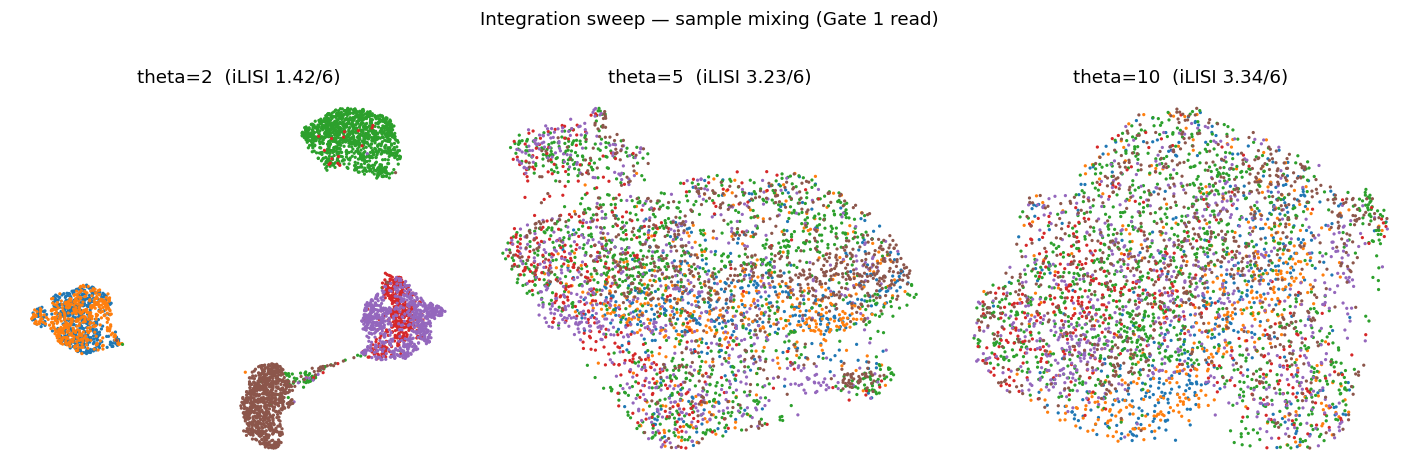

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, th in zip(axes, [2,5,10]):
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    adata.obsm[f'X_umap_th{th}'] = adata.obsm['X_umap'].copy()
    sc.pl.umap(adata, color='sample', size=18, frameon=False, show=False, ax=ax,
               title=f'theta={th}  (iLISI {grid[(th,20)]:.2f}/{nb})')
    lg = ax.get_legend()
    if lg is not None: lg.remove()
fig.suptitle('Integration sweep — sample mixing (Gate 1 read)', y=1.02)
fig.tight_layout()
print('theta=2: per-sample archipelago (segregated). theta=5: one connected mass, mixing.'
      ' theta=10: fully intermixed single continuous cloud -> commit theta=10.')

In [8]:
# commit theta=10 embedding
adata.obsm['X_umap'] = adata.obsm['X_umap_th10'].copy()
for k in ['X_umap_th2','X_umap_th5','X_umap_th10']: del adata.obsm[k]

### Island removal — radius graph on the UMAP
Strictly conservative: keep the largest connected component of a radius graph at 6× the median nearest-neighbour distance.

In [9]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)

removed 0 cells in 0 detached islands


### Sub-region biology before the GO (lobe identity + cell cycle)
Leiden at 0.15 to test whether the manifold resolves into distinct compartments (e.g. an embryonic vs a cycling lobe, as in Kürten). Cell-cycle phase and the proliferation↔signature confound are checked before certifying continuity.

In [10]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', dict(adata.obs['lobe'].value_counts()))
print('cell-cycle phase:', dict(adata.obs['cell_cycle_phase'].astype(str).value_counts()))
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print(f'-> single connected compartment at res 0.15; {adata.obs["cycling"].mean()*100:.0f}% cycling '
      'cells are dispersed, not a separate lobe. No sub-region to scope out.')

lobe sizes: {'0': np.int64(3936)}
cell-cycle phase: {'Not cycling': np.int64(3212), 'G1/S': np.int64(337), 'G2/M': np.int64(261), 'Intermediate': np.int64(126)}
cycling fraction per lobe: {'0': 0.184}
-> single connected compartment at res 0.15; 18% cycling cells are dispersed, not a separate lobe. No sub-region to scope out.


### Gate 1 diagnostic — sample / lobe / cell cycle on the committed embedding

6 samples share one continuous, intermixed manifold; one connected component retained.
Gate 1: MIXED (iLISI plateau, samples interspersed) + CONTINUOUS (single component) -> GO


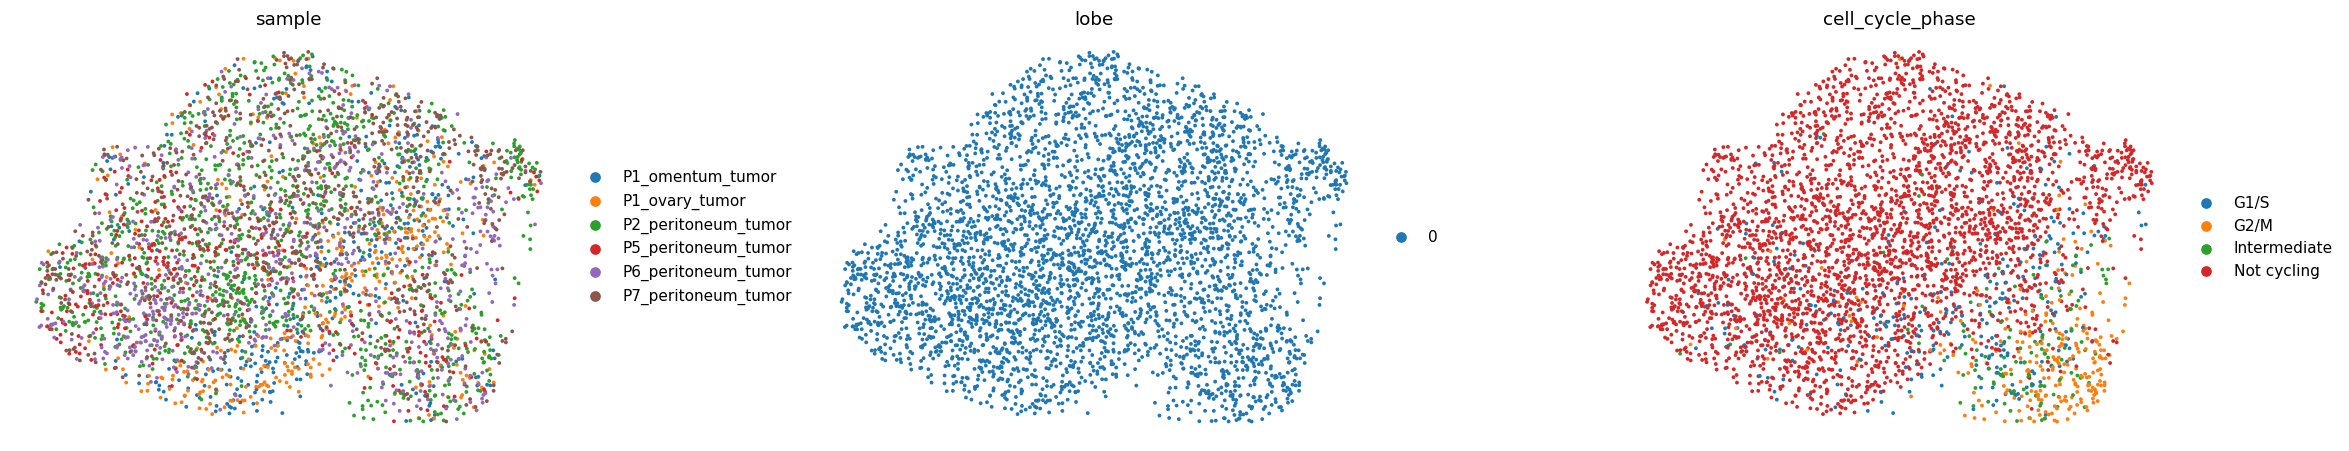

In [11]:
fig = sc.pl.umap(adata, color=['sample','lobe','cell_cycle_phase'],
                 size=25, wspace=.32, frameon=False, show=False)
print(f'{adata.obs["sample"].nunique()} samples share one continuous, intermixed manifold; '
      'one connected component retained.')
print('Gate 1: MIXED (iLISI plateau, samples interspersed) + CONTINUOUS (single component) -> GO')

In [12]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3936, 22675)


### Deliverable — `samples.pdf`
House `(3.5,1.5)` manifold strip, coloured by `sample`. Intermixing across the manifold is the Gate-1 batch-integration evidence (direction immaterial for this categorical panel; the oriented linear layout is set in 02 once pseudotime exists).

saved samples.pdf | cells: 3936


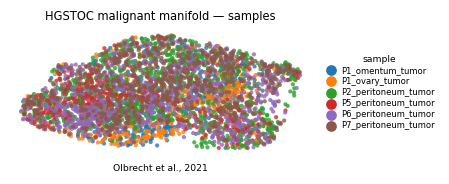

In [13]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('HGSTOC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Olbrecht et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])